# ML-09b (Python) — Évaluer des détecteurs sur cinq séries UCR

**Navigation** · [ML-09 →](ML-09-Anomaly-Detection-Python.ipynb) · [ML-09c →](ML-09c-MatrixProfile-Multidim-Python.ipynb)

[Jumeau C#](ML-09b-TSAD-Benchmark-Flaws-CSharp.ipynb) · [Index](README.md)

**Objectifs** : comparer SPC et un MLP de prévision, distinguer classement et seuil, mesurer densité, dépendance aux étiquettes et biais de position. **Prérequis** : moyenne, écart-type, ROC/AUC et fenêtres temporelles. **Durée** : 90 minutes.

Les cinq séries réelles et tous les budgets de ce carnet sont conservés. Les expériences illustrent des mécanismes de métriques ; elles ne reproduisent pas les évaluations externes du contexte bibliographique ci-dessous et ne démontrent pas que toute une archive est « honnête » ou « triviale ».

## Une discipline qui s'interroge : Wu & Keogh (2020)

La source conserve la référence historique à Wu & Keogh, *Current Time Series Anomaly Detection Benchmarks are Flawed and are Creating the Illusion of Progress* (arXiv:2009.13807, IEEE TKDE 2021). Les évaluations de cet article ne sont pas reproduites ici.

Les calculs locaux comparent SPC et un MLP de prévision sur trois séries parmi cinq fichiers UCR réels, puis examinent densité, sensibilité aux annotations et position de l'événement. Ils décrivent les résultats de ce protocole ; une victoire de SPC ne prouve pas la trivialité générale d'un benchmark, et un échec des deux méthodes ne certifie pas son honnêteté. Le MLP exécuté prédit une valeur future et n'est pas un auto-encodeur.

## 1. Le détecteur SPC en NumPy (algorithme de 1924)

On calcule le score absolu centré-réduit ; le seuil strict >3 constitue une décision distincte de son AUC de classement. Moyenne et écart-type sont estimés sur la série complète : c'est un diagnostic descriptif/transductif, sans entraînement paramétrique de réseau, mais pas un détecteur prospectif sans accès au futur.

La règle vectorisée de décision reste visible indépendamment du chargeur :

```python
# Coeur du détecteur SPC — une seule ligne
anomalie = np.abs(x - x.mean()) > 3 * x.std()
```

Elle utilise les moments de toute la série ; « anomalie » désigne ici une alerte de la règle, pas une vérité terrain. Le score continu et l'AUC sont calculés séparément.

### Charger une série réelle de l'UCR Archive

Le chargeur existant lit l'archive UCR par HTTP Range, vérifie taille et SHA-256 contre `ucr_anomaly_manifest.json`, puis cache les octets dans `data/tsad` ignoré par Git. Aucun remplacement synthétique si réseau/intégrité échoue, aucune redistribution des séries dans le dépôt. Les indices début/fin inclusifs du nom définissent les étiquettes. Le champ précédent est l'indication de train de l'archive ; ce notebook conserve son protocole propre de première moitié pour le MLP, distinct de ce découpage officiel.

Série : tiltAPB4 | longueur = 128001 | points anormaux = 2 (0.0016%)

SPC (M + 3*σ, 1924) : AUC = 0.998
  prédictions > 3σ : 1569 points, dont 2 vrais anormaux


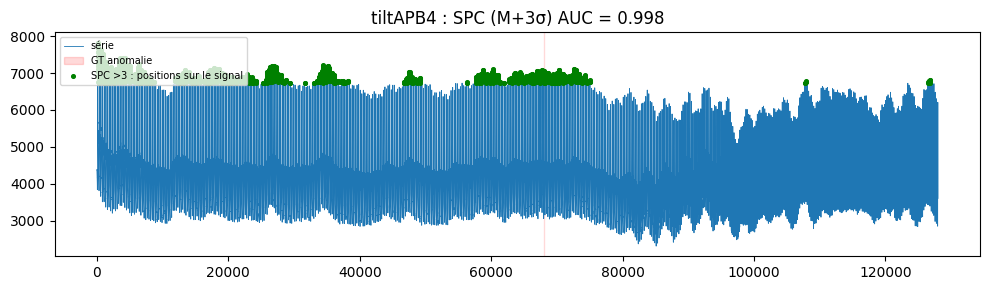

In [1]:
import os, re, sys, numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

np.random.seed(42)          # reproductibilite (cf. ML-09)

# Les series UCR ne sont PAS versionnees : l'archive (184 Mo) n'est couverte
# par aucune licence de redistribution -- sa page n'enonce qu'une citation
# suggeree. On lit donc chaque serie a l'execution par requetes HTTP Range
# (cf. ucr_anomaly_fetch.py), et on la met en cache dans un dossier ignore
# par git. Voir .claude/rules/bibliography-hygiene.md.
sys.path.insert(0, os.getcwd())
from ucr_anomaly_fetch import fetch_raw   # leve UcrFetchError si le reseau echoue

CACHE_DIR = os.path.join('data', 'tsad')   # cache local, non versionne

def parse_name(name):
    """Extraire (nom, debut, fin) de l'anomalie depuis le nom de fichier UCR."""
    m = re.match(r'\d+_UCR_Anomaly_(.+)_\d+_(\d+)_(\d+)\.txt', name)
    return m.group(1), int(m.group(2)), int(m.group(3))

def load_series(name):
    """Charger une serie UCR + son masque GT (intervalle [debut, fin]).

    Les octets viennent de l'archive UCR par lecture partielle ; si le serveur
    ne repond pas, `UcrFetchError` remonte telle quelle. Aucune serie de
    substitution n'est fabriquee : un benchmark sur des donnees inventees ne
    demontrerait rien -- c'est le travers meme que ce notebook documente.
    """
    vals = []
    for line in fetch_raw(name, cache_dir=CACHE_DIR).decode('utf-8', 'replace').splitlines():
        for tok in line.replace(',', ' ').split():
            try: vals.append(float(tok))
            except ValueError: pass
    x = np.asarray(vals)
    ds, s, e = parse_name(name)
    labels = np.zeros(len(x))
    s, e = max(0, s), min(e, len(x) - 1)
    labels[s:e + 1] = 1.0
    return x, labels, ds

def auc(labels, scores):
    """AUC (area under ROC) robuste aux égalités, par la statistique de Mann-Whitney."""
    pos, neg = scores[labels == 1], scores[labels == 0]
    if len(pos) == 0 or len(neg) == 0: return float('nan')
    ns = np.sort(neg)
    right = np.searchsorted(ns, pos, side='right')
    left = np.searchsorted(ns, pos, side='left')
    return float((right.sum() - 0.5 * (right - left).sum()) / (len(pos) * len(neg)))

def spc_scores(x):
    """Score SPC : écart absolu en unités d'écart-type. SPC = score > 3."""
    return np.abs(x - x.mean()) / max(x.std(), 1e-12)

# Série réelle à anomalie PONCTUELLE (SPC devrait bien la détecter)
SERIE_PONCTUELLE = '200_UCR_Anomaly_tiltAPB4_20000_67995_67996.txt'
x, lab, ds = load_series(SERIE_PONCTUELLE)
print(f'Série : {ds} | longueur = {len(x)} | points anormaux = {int(lab.sum())} '
      f'({100 * lab.sum() / len(x):.4f}%)')

spc = spc_scores(x)
auc_spc = auc(lab, spc)
print(f'\nSPC (M + 3*σ, 1924) : AUC = {auc_spc:.3f}')
print(f'  prédictions > 3σ : {(spc > 3).sum()} points, dont {(spc[lab == 1] > 3).sum()} vrais anormaux')

plt.figure(figsize=(10, 3))
plt.plot(x, lw=0.6, label='série')
plt.axvspan(lab.argmax(), len(lab) - lab[::-1].argmax(), color='red', alpha=0.15, label='GT anomalie')
alert_idx = np.flatnonzero(spc > 3)
plt.scatter(alert_idx, x[alert_idx], s=7, color='green', label='SPC >3 : positions sur le signal', zorder=3)
plt.title(f'{ds} : SPC (M+3σ) AUC = {auc_spc:.3f}')
plt.legend(loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()

### Interprétation — classement et seuil

L'AUC SPC et les nombres d'alertes/vrais positifs sont imprimés séparément. Une AUC élevée classe les deux points étiquetés vers le haut ; elle ne prouve pas que le seuil >3 les trouve tous sans fausses alertes. La réussite d'une méthode simple sur une seule série ne suffit pas à établir la qualité de toute une archive.

## 2. MLP de prévision à partir de fenêtres

Le modèle réel `MLPRegressor` prédit une valeur scalaire à partir de 20 observations : il n'est pas un auto-encodeur reconstruisant sa propre entrée. L'alignement historique est conservé exactement : X[i]=x[i:i+20], y[i]=x[i+21], donc deux pas après le dernier point observé. Les 21 premiers scores sont nuls par convention, sans prédiction disponible.

On conserve 32 neurones, maximum 1200 itérations, graine 0, early_stopping, patience 30 et pas 1e-3. Les fenêtres de la première moitié servent à ajuster **aussi le StandardScaler**, puis le réseau ; la seconde moitié n'ajuste ni scaler ni réseau. Cette correction retire la fuite de normalisation héritée. L'hypothèse que la moitié d'entraînement est saine reste à examiner. L'AUC affichée sur la série complète inclut les scores du train et les préfixes nuls : ce n'est pas une mesure exclusivement holdout.

MLP de prévision (MLPRegressor) : AUC = 0.901
SPC (1924) : AUC = 0.998

Comparaison : SPC passe devant le MLP de prévision (écart 0.097) sur ce benchmark.


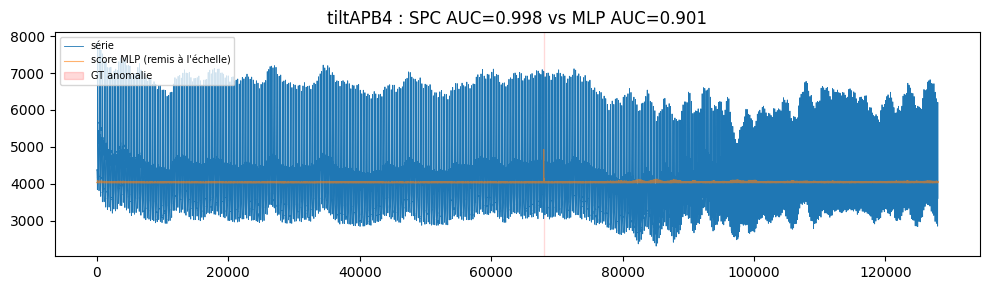

In [2]:
def ae_recon_scores(x, window=20, hidden=(32,), seed=0):
    """Score par erreur de prévision : 20 observations puis cible à deux pas.
       Scaler et réseau ajustés sur la première moitié des fenêtres (supposée saine)."""
    if len(x) < window + 5: return np.zeros(len(x))
    X = np.array([x[i:i + window] for i in range(len(x) - window - 1)])
    y = x[window + 1:]
    cut = len(X) // 2
    sc = StandardScaler().fit(X[:cut])
    Xs = sc.transform(X)
    reg = MLPRegressor(hidden_layer_sizes=hidden, max_iter=1200, random_state=seed,
                       early_stopping=True, n_iter_no_change=30, learning_rate_init=1e-3)
    reg.fit(Xs[:cut], y[:cut])
    err = np.abs(reg.predict(Xs) - y)
    scores = np.zeros(len(x))
    scores[window + 1: window + 1 + len(err)] = err
    return scores

ae = ae_recon_scores(x)          # même série tiltAPB4 que ci-dessus
auc_ae = auc(lab, ae)
print(f'MLP de prévision (MLPRegressor) : AUC = {auc_ae:.3f}')
print(f'SPC (1924) : AUC = {auc_spc:.3f}')
print(f'\nComparaison : SPC {"passe devant" if auc_spc > auc_ae else "derrière"} le MLP de prévision '
      f'(écart {abs(auc_spc - auc_ae):.3f}) sur ce benchmark.')

plt.figure(figsize=(10, 3))
plt.plot(x, lw=0.6, label='série')
plt.plot(ae / max(ae.max(), 1e-12) * x.std() + x.mean(), lw=0.8, alpha=0.6, label='score MLP (remis à l\'échelle)')
plt.axvspan(lab.argmax(), len(lab) - lab[::-1].argmax(), color='red', alpha=0.15, label='GT anomalie')
plt.title(f'{ds} : SPC AUC={auc_spc:.3f} vs MLP AUC={auc_ae:.3f}')
plt.legend(loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()

### Interprétation : la complexité n'a rien acheté *ici*

Sur `tiltAPB4`, SPC obtient une AUC de **0.998** et le MLP de prévision **0.901**, soit un écart de **0.097**. Cette baseline simple classe donc mieux les deux points annotés dans cette expérience. Au seuil >3, elle signale cependant **1569 points**, dont seulement **2 vrais anormaux** : un bon classement ne suffit pas à faire une bonne décision au seuil.

L'écart décrit ce protocole, sans prouver qu'un réseau est inutile ni que le benchmark est intrinsèquement trivial. Aucun temps d'apprentissage comparatif contrôlé n'est mesuré ici. Pour examiner un autre type de signal, on réapplique ensuite les mêmes modèles à `InternalBleeding16`, où l'événement est un décalage de niveau persistant plutôt qu'un pic isolé.


InternalBleeding16 : anomalie par décalage de niveau (contextuelle)
  SPC AUC = 0.201   MLP AUC = 0.973
  → le MLP de prévision rattrape le SPC ici : comparaison descriptive sur cette série, sans verdict général sur les benchmarks.


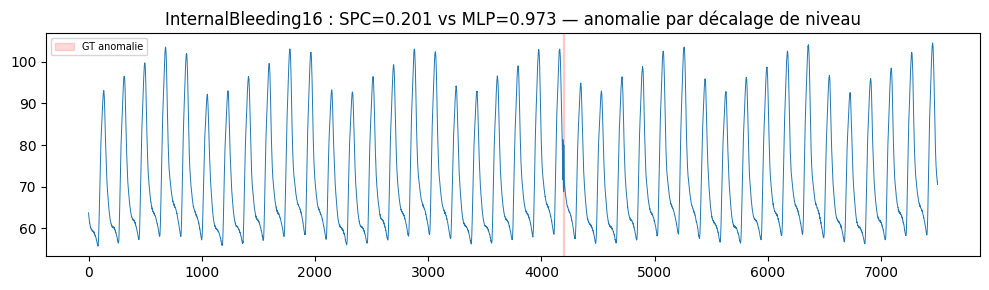

In [3]:
# Comparaison descriptive des deux scores sur InternalBleeding16
SERIE_CONTEXTUELLE = '135_UCR_Anomaly_InternalBleeding16_1200_4187_4199.txt'
x2, lab2, ds2 = load_series(SERIE_CONTEXTUELLE)
auc_spc2 = auc(lab2, spc_scores(x2))
auc_ae2 = auc(lab2, ae_recon_scores(x2))
print(f'{ds2} : anomalie par décalage de niveau (contextuelle)')
print(f'  SPC AUC = {auc_spc2:.3f}   MLP AUC = {auc_ae2:.3f}')
print(f'  → le MLP de prévision {"rattrape" if auc_ae2 > auc_spc2 else "ne bat pas"} le SPC ici : '
      f'comparaison descriptive sur cette série, sans verdict général sur les benchmarks.')

plt.figure(figsize=(10, 3))
plt.plot(x2, lw=0.7)
plt.axvspan(np.argmax(lab2), len(lab2) - lab2[::-1].argmax(), color='red', alpha=0.15, label='GT anomalie')
plt.title(f'{ds2} : SPC={auc_spc2:.3f} vs MLP={auc_ae2:.3f} — anomalie par décalage de niveau')
plt.legend(loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()

### Ponctuelle vs contextuelle : la ligne de partage

Sur `InternalBleeding16`, l'AUC de SPC est **0.201**, celle du MLP **0.973**. L'ordre est inversé par rapport à `tiltAPB4`. SPC mesure l'écart à une moyenne et un écart-type globaux : un changement de régime prolongé participe lui-même à ces statistiques. Le MLP exploite une fenêtre de 20 observations pour prévoir une valeur future ; il ne reconstruit pas sa fenêtre comme un auto-encodeur.

Ces mécanismes aident à lire le contraste entre statistique globale et contexte local. Les résultats ne prouvent cependant ni une impossibilité universelle de SPC face à un décalage, ni une causalité exclusive du contexte dans l'écart d'AUC. La nature de l'anomalie, les étiquettes, la moitié choisie pour l'entraînement et la métrique contribuent ensemble au résultat. Un protocole doit couvrir plusieurs formes d'événement avant de généraliser cette comparaison.


### Exercice 1 — Contraste SPC entre zone étiquetée et fond

Sur InternalBleeding16, calculez l'AUC SPC, le pic intérieur, le 99e centile extérieur, le nombre total d'alertes>3 et de vrais positifs. Implémentez cette analyse pour des valeurs/étiquettes quelconques. Le garde utilise la série réelle et trois petites fixtures. Comparez le résultat au MLP et expliquez ce qu'une AUC dit et ne dit pas du seuil ; ne postulez pas l'échec de SPC avant le calcul.

> **TODO étudiant :**
> Complétez la fonction de la cellule suivante ; le garde contrôle les calculs, puis votre interprétation reste à argumenter.


In [4]:
def verifier_diagnostic(fonction):
    essais=[(np.r_[np.zeros(19),10.],np.r_[np.zeros(19,dtype=int),1]),(x2,lab2),(np.array([0.,0,0,0,4,0,-4,0,0,0]),np.array([0,0,0,0,1,0,1,0,0,0])),(np.arange(1.,9.),np.array([0,0,0,0,0,0,1,1]))]
    try:
        for valeurs,labels in essais:
            z=spc_scores(valeurs);expected=[auc(labels,z),z[labels==1].max(),np.quantile(z[labels==0],.99),int((z>3).sum()),int(((z>3)&(labels==1)).sum())]
            result=fonction(valeurs.copy(),labels.copy())
            if result is None: return False
            a=np.asarray(result,dtype=float)
            if a.shape!=(5,) or not np.isfinite(a).all() or not np.allclose(a,expected,atol=1e-10,rtol=0):return False
        return True
    except (TypeError,ValueError,IndexError):return False

def diagnostic_spc(valeurs,labels):
    return None  # TODO : AUC, pic intérieur, p99 extérieur, alertes et vrais positifs

print("Exercice1 à compléter" if diagnostic_spc(x2,lab2) is None else f"Diagnostic valide : {verifier_diagnostic(diagnostic_spc)}")

Exercice1 à compléter


## 3. Les 4 pièges des benchmarks (Wu & Keogh)

### Piège 1 — Trivialité

On réaffiche SPC sur tiltAPB4 et son AUC. Une baseline compétitive impose de justifier la complexité supplémentaire ; elle ne démontre pas à elle seule qu'un benchmark ne mesure rien. Classement et décision au seuil restent deux questions.

In [5]:
# Baseline SPC : score et décision distincts
x1, lab1, ds1 = load_series('200_UCR_Anomaly_tiltAPB4_20000_67995_67996.txt')
anomalie = np.abs(x1 - x1.mean()) > 3 * x1.std()     # UNE ligne
print(f'{ds1} : AUC de cette ligne = {auc(lab1, np.abs(x1 - x1.mean()) / x1.std()):.3f}')
print('  Classement SPC à comparer séparément aux décisions du seuil >3.')
print(f'  Rappel : le MLP de prévision entraîné obtient {auc_ae:.3f} sur la même série.')


tiltAPB4 : AUC de cette ligne = 0.998
  Classement SPC à comparer séparément aux décisions du seuil >3.
  Rappel : le MLP de prévision entraîné obtient 0.901 sur la même série.


### 2 — Densité des étiquettes

Mesurons la fraction étiquetée positive dans les cinq séries UCR. Une densité plausible dépend du contexte et de la définition de l'événement : aucun seuil universel 1%/5% n'est établi par ces seules données. Une forte prévalence peut gonfler l'accuracy d'une prédiction majoritaire ; l'AUC d'un score constant reste 0.5 quand les deux classes sont présentes.

In [6]:
# Piège 2 : Densité d'anomalies réelle vs irréaliste
series = ['200_UCR_Anomaly_tiltAPB4_20000_67995_67996.txt',
          '162_UCR_Anomaly_WalkingAceleration5_2700_5920_5979.txt',
          '248_UCR_Anomaly_weallwalk_2000_4702_4707.txt',
          '135_UCR_Anomaly_InternalBleeding16_1200_4187_4199.txt',
          '110_UCR_Anomaly_2sddb40_35000_56600_56900.txt']
print('Densité d\'anomalies des séries réelles UCR (extrait) :')
dens = []
for s in series:
    _, l, n = load_series(s)
    d = 100 * l.sum() / len(l)
    dens.append(d)
    print(f'  {n:24s} {d:7.4f}%')
print(f'\nMédiane : {np.median(dens):.4f}% (sur ces cinq séries)')
print('La densité seule ne mesure ni qualité des annotations ni difficulté ROC.')


Densité d'anomalies des séries réelles UCR (extrait) :
  tiltAPB4                  0.0016%
  WalkingAceleration5       0.8977%
  weallwalk                 0.0712%
  InternalBleeding16        0.1733%
  2sddb40                   0.3762%

Médiane : 0.1733% (sur ces cinq séries)
La densité seule ne mesure ni qualité des annotations ni difficulté ROC.


### Pourquoi distinguer densité et métrique ?

Les densités imprimées vont de **0.0016%** pour `tiltAPB4` à **0.8977%** pour `WalkingAceleration5` ; la médiane de ces cinq séries vaut **0.1733%**. Il s'agit de cet extrait de cinq fichiers, sans généralisation à toute l'archive ni validation clinique ou industrielle de ces fréquences.

Une forte asymétrie de classes rend élevée l'accuracy d'une règle majoritaire : max(p, 1−p) pour une densité d'anomalies p. Elle ne rend pas automatiquement le classement ROC trivial : avec les deux classes présentes, un score constant donne une AUC de 0.5. Inversement, une densité faible ne garantit ni la qualité des annotations ni la difficulté d'un benchmark. L'exercice ci-dessous confronte densité, accuracy des règles constantes et AUC constante sur les mêmes étiquettes.


### Exercice 2 — Densité et règles constantes

Implémentez une fonction renvoyant densité positive, accuracy « tout normal », accuracy « tout anormal » et AUC d'un score constant. Comparez la série UCR rare à des étiquettes artificielles 50% positives, puis concluez sur la plausibilité de la densité pour un contexte choisi. Pourquoi le changement de prévalence ne suffit-il pas à rendre l'AUC constante élevée ?

> **TODO étudiant :**
> Complétez la fonction de la cellule suivante ; le garde contrôle les calculs, puis votre interprétation reste à argumenter.


In [7]:
def verifier_densite(fonction):
    try:
        for labels in [lab,np.array([0,0,0,1]),np.array([0,0,1,1]),np.array([0,1,1,1])]:
            d=float(np.mean(labels));expected=np.array([d,1-d,d,.5]);result=fonction(labels.copy())
            if result is None:return False
            a=np.asarray(result,dtype=float)
            if a.shape!=(4,) or not np.isfinite(a).all() or not np.allclose(a,expected,atol=1e-12,rtol=0):return False
        return True
    except (TypeError,ValueError):return False

def analyser_densite(labels):
    return None  # TODO : densité, accuracy tout normal/tout anormal, AUC constante

print("Exercice2 à compléter" if analyser_densite(lab) is None else f"Mesures valides : {verifier_densite(analyser_densite)}")

Exercice2 à compléter


### 3 — Sensibilité aux étiquettes

Décalons les étiquettes de `WalkingAceleration5` de 0, 30 et 120 indices en conservant le signal et le score SPC. Les AUC mesurées sont respectivement **0.962**, **0.778** et **0.417**. Le détecteur n'a donc pas changé ; seule la région tenue pour positive a été déplacée.

Cette expérience montre la dépendance de l'évaluation aux annotations. Un décalage artificiel n'est toutefois pas la preuve d'une erreur de vérité terrain dans ce fichier : il construit des annotations alternatives pour éprouver la métrique. Aucun jeu Yahoo externe n'est chargé ni évalué ici. Avant d'attribuer une variation de score au modèle, il faut donc examiner la convention d'étiquetage et l'alignement temporel.


In [8]:
# Piège 3 : Fragilité aux étiquettes — le même détecteur, une étiquette décalée
def shift_labels(labels, shift):
    """Décaler la fenêtre GT de `shift` positions (étiquette décalée = erreur d'annotation)."""
    y = np.zeros_like(labels)
    idx = np.where(labels == 1)[0]
    if len(idx) == 0: return y
    lo, hi = idx[0], idx[-1]
    lo2, hi2 = max(0, lo + shift), min(len(labels) - 1, hi + shift)
    y[lo2:hi2 + 1] = 1
    return y

x3, lab3, ds3 = load_series('162_UCR_Anomaly_WalkingAceleration5_2700_5920_5979.txt')
sc = spc_scores(x3)
print(f'{ds3} : AUC de SPC selon le décalage de l\'étiquette GT :')
for sh in [0, 30, 120]:
    a = auc(shift_labels(lab3, sh), sc)   # étiquette décalée = erreur d'annotation
    print(f'  décalage {sh:4d} : AUC = {a:.3f}')
print('Même série et même score : les AUC varient avec les étiquettes artificiellement décalées.')


WalkingAceleration5 : AUC de SPC selon le décalage de l'étiquette GT :
  décalage    0 : AUC = 0.962
  décalage   30 : AUC = 0.778
  décalage  120 : AUC = 0.417
Même série et même score : les AUC varient avec les étiquettes artificiellement décalées.


### Piège 4 — Biais « run-to-failure »

La baseline donne un score croissant avec l'indice, sans regarder le signal. Une anomalie tardive tend alors à obtenir un classement favorable. L'AUC mesurée sur WalkingAceleration5 décrit cet avantage de position, pas une capacité à reconnaître une forme anormale.

WalkingAceleration5 : anomalie à 89% de la série (tardive)
  baseline run-to-failure : AUC = 0.894   (score indépendant du signal)
  Vrai détecteur SPC sur la même série : AUC = 0.962
Le score mesure ici un avantage de position, sans examiner le contenu du signal.


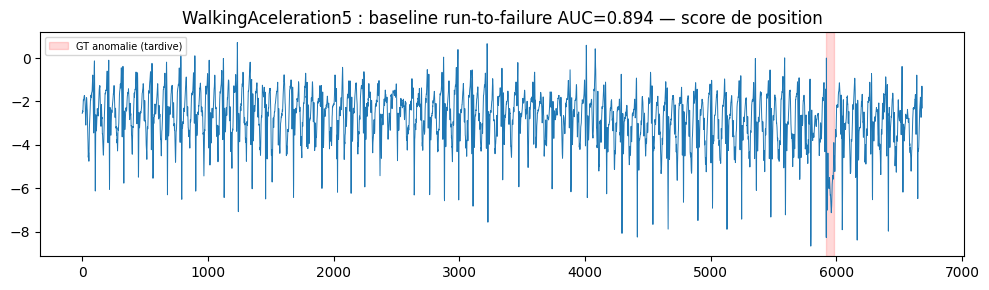

In [9]:
# Piège 4 : Run-to-failure — « prédire la fin » sans rien détecter
def run_to_failure_scores(labels):
    """Baseline dégénérée : score croissant vers la fin (prédit que la fin est anormale)."""
    return np.linspace(0, 1, len(labels))

# WalkingAceleration5 : l'anomalie est à ~89% de la série (presque à la fin)
x4, lab4, ds4 = load_series('162_UCR_Anomaly_WalkingAceleration5_2700_5920_5979.txt')
rtf = run_to_failure_scores(lab4)
print(f'{ds4} : anomalie à {100*lab4.argmax()/len(lab4):.0f}% de la série (tardive)')
print(f'  baseline run-to-failure : AUC = {auc(lab4, rtf):.3f}   (score indépendant du signal)')
print(f'  Vrai détecteur SPC sur la même série : AUC = {auc(lab4, spc_scores(x4)):.3f}')
print('Le score mesure ici un avantage de position, sans examiner le contenu du signal.')

plt.figure(figsize=(10, 3))
plt.plot(x4, lw=0.7)
plt.axvspan(np.argmax(lab4), len(lab4) - lab4[::-1].argmax(), color='red', alpha=0.15, label='GT anomalie (tardive)')
plt.title(f'{ds4} : baseline run-to-failure AUC={auc(lab4, rtf):.3f} — score de position')
plt.legend(loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()

### Comment ce biais gonfle les scores

L'anomalie de `WalkingAceleration5` commence à **89%** de la série. Une baseline croissante avec l'indice obtient une AUC de **0.894**, contre **0.962** pour SPC, alors qu'elle ne lit aucune valeur du signal. Elle est favorisée par la position tardive des points positifs, sans reconnaître la forme de l'anomalie.

Un protocole qui placerait systématiquement les événements en fin de trace pourrait ainsi récompenser un score dépourvu de capacité de détection du contenu. Varier les positions et comparer les modèles à cette baseline aide à repérer cette dépendance. Une supériorité sur cette référence reste un contrôle du protocole, sans marge universelle à imposer ni garantie suffisante de qualité du modèle.


### Exercice 3 — Effet de la position de l'événement

L'exemple de baseline croissante est conservé plus haut. Ajoutez une fonction calculant son AUC pour une région positive inclusive [début,fin] dans une série de longueur n. Testez début, milieu et toute fin, sans utiliser les valeurs du signal. Le garde varie n et largeur ; montrez sur une série factice que la région finale obtient une AUC élevée et expliquez pourquoi ce score est trompeur pour la détection du contenu.

> **TODO étudiant :**
> Complétez la fonction de la cellule suivante ; le garde contrôle les calculs, puis votre interprétation reste à argumenter.


In [10]:
def verifier_position(fonction):
    try:
        for n,debut,fin in [(100,90,99),(100,0,9),(60,20,25),(80,51,73)]:
            labels=np.zeros(n);labels[debut:fin+1]=1
            attendu=auc(labels,run_to_failure_scores(labels));result=fonction(n,debut,fin)
            if result is None or not np.isfinite(result) or abs(float(result)-attendu)>1e-12:return False
        return True
    except (TypeError,ValueError,IndexError):return False

def effet_position(n,debut,fin):
    return None  # TODO : AUC du score croissant pour l'intervalle étiqueté

print("Exercice3 à compléter" if effet_position(100,90,99) is None else f"Positions valides : {verifier_position(effet_position)}")

Exercice3 à compléter


## 4. Changer de série : 2sddb40

On conserve les mêmes scores SPC et MLP et leur entraînement sur première moitié. Une AUC faible ne certifie pas qu'un jeu est « honnête » : elle mesure le classement de cette méthode pour ces étiquettes. Aucun résultat attendu n'est forcé par le code.


2sddb40 : anomalie collective (anomalie = 0.4% de la série)
  SPC AUC = 0.172   (≈ hasard si ~0.5)
  MLP AUC = 0.355
Ces AUC décrivent les deux classements, sans certifier la qualité du benchmark.


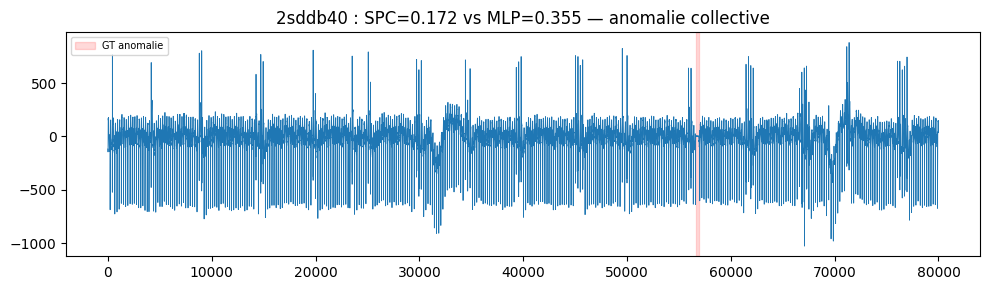

In [11]:
# Comparaison des deux scores sur 2sddb40
x6, lab6, ds6 = load_series('110_UCR_Anomaly_2sddb40_35000_56600_56900.txt')
spc6 = spc_scores(x6)
ae6 = ae_recon_scores(x6)
print(f'{ds6} : anomalie collective (anomalie = {100*lab6.sum()/len(lab6):.1f}% de la série)')
print(f'  SPC AUC = {auc(lab6, spc6):.3f}   (≈ hasard si ~0.5)')
print(f'  MLP AUC = {auc(lab6, ae6):.3f}')
print('Ces AUC décrivent les deux classements, sans certifier la qualité du benchmark.')

plt.figure(figsize=(10, 3))
plt.plot(x6, lw=0.6)
plt.axvspan(np.argmax(lab6), len(lab6) - lab6[::-1].argmax(), color='red', alpha=0.15, label='GT anomalie')
plt.title(f'{ds6} : SPC={auc(lab6, spc6):.3f} vs MLP={auc(lab6, ae6):.3f} — anomalie collective')
plt.legend(loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()

### Interprétation — lire le résultat sans qualifier le benchmark

Sur `2sddb40`, SPC obtient une AUC de **0.172** et le MLP **0.355**. Les deux scores classent ici les points positifs moins haut que les négatifs en moyenne, sous la convention « grand score = anomalie ». Une AUC<0.5 décrit ce classement inversé ; une AUC proche de 0.5 ne suffirait pas non plus à établir l'absence de toute information dans le signal.

Le contraste avec `tiltAPB4` montre que le même algorithme change fortement de résultat selon la série. Il ne démontre pas que la première série ne mesurait rien, que les anomalies collectives exigent une méthode unique ou qu'une performance élevée serait suspecte par nature. Les découpages, labels et modèles restent à examiner séparément.


### Comparaison limitée à ces données

Les écarts entre `tiltAPB4`, `InternalBleeding16` et `2sddb40` montrent la dépendance du résultat à la série et au protocole. La comparaison conserve les cinq fichiers réels pour les diagnostics de densité, mais les trois ajustements MLP ne constituent ni une validation sur toute l'archive, ni une étude exhaustive d'hyperparamètres, ni une comparaison statistique multi-graines.

Les cas ponctuel, contextuel et collectif aident à varier les situations étudiées. Aucune victoire d'une baseline simple ne certifie à elle seule la trivialité d'un benchmark ; aucun échec des deux méthodes n'en certifie l'honnêteté. Enfin, l'ajustement sans fuite du scaler et du MLP ne transforme pas le score SPC global, calculé avec toute la série, en détecteur prospectif.


## 5. Le constat étendu (2024-2025) : l'introspection continue

Le problème ne s'est pas arrêté en 2020. En **2024**, Liu & Paparrizos publient *« The Elephant in the Room: Towards A Reliable Time-Series Anomaly Detection Benchmark »* (NeurIPS 2024, *Datasets & Benchmarks Track*) avec **TSB-AD-M**. En **2025**, Keogh (l'un des auteurs de 2020) signale sur [un fil r/MachineLearning](https://www.reddit.com/r/MachineLearning/comments/1w1wt1s/you_can_beat_sota_time_series_anomaly_detection/) que la **baseline SPC de 1924 bat le SOTA** sur TSB-AD-M et obtient des résultats parfaits sur certaines traces ECG. La communauté s'interroge encore.

> **Le statut de cette dernière source, et pourquoi on s'y arrête.** Le fil Reddit est un **message de forum, pas une publication archivée** : ni relecture par les pairs, ni DOI, ni garantie de permanence — demain le fil peut être supprimé. On le cite parce qu'il est *daté et attribuable*, et parce qu'il montre que l'introspection continue ; mais la thèse de fond qu'il illustre, elle, repose sur l'article archivé de 2020 (arXiv:2009.13807), pas sur le fil. Un notebook qui enseigne à se méfier d'un score sans regarder comment il est mesuré se doit d'appliquer la même exigence à ses propres sources : distinguer ce qui est **établi** de ce qui est **rapporté**.

**La morale transversale :** avant de s'extasier sur un score, regarder **comment il est mesuré** — la trivialité, la densité, l'étiquetage et la chronologie (run-to-failure) peuvent tous gonfler un score sans que le modèle ait rien appris.

**Alternative au deep learning** : le **Matrix Profile** (calcul d'un motif de similarité le long de la série) n'apprend pas, mais modélise le contexte local — il est fait pour les anomalies contextuelles/collectives. C'est l'objet du notebook [ML-09c](ML-09c-MatrixProfile-Multidim-Python.ipynb).



**Limite locale.** Aucun protocole TSB-AD, aucun modèle de ce fil et aucun résultat de publication externe ne sont exécutés ici. Un profil sans ajustement paramétrique reste sensible aux hyperparamètres et au choix du protocole.

## Résumé

- Une AUC de classement et un résultat au seuil>3 sont distincts.
- SPC global utilise les données complètes ; le MLP ajuste scaler/réseau sur sa première moitié uniquement.
- Densité, annotations et position influencent des métriques différentes et doivent être explicitées.
- Les expériences portent sur cinq séries, trois ajustements MLP et une seule graine, pas sur toute une littérature.

## À retenir
La méthode, ses données, son découpage et sa métrique définissent ensemble le résultat.

## Vérifiez votre compréhension
Un score constant a-t-il une AUC élevée quand 80% des points sont anormaux ?
<details><summary>Réponse</summary>Non : avec les deux classes, tous les rangs sont ex æquo et l'AUC vaut 0.5 ; une règle constante peut cependant avoir une accuracy de 80%.</details>

## Pour aller plus loin
Poursuivez avec [ML-09c — Matrix Profile](ML-09c-MatrixProfile-Multidim-Python.ipynb).

## Références

- Wu, R. & Keogh, E. J. (2020/2021). *Current Time Series Anomaly Detection Benchmarks are Flawed and are Creating the Illusion of Progress*. arXiv:2009.13807, IEEE TKDE 2021.
- Keogh, E. (2025). Fil [r/MachineLearning](https://www.reddit.com/r/MachineLearning/comments/1w1wt1s/you_can_beat_sota_time_series_anomaly_detection/) : la baseline SPC (1924) bat le SOTA sur TSB-AD-M. **Source non archivée** — message de forum, sans relecture par les pairs : citée pour la traçabilité de l'affirmation 2025, elle ne porte aucun des résultats mesurés dans ce notebook (voir l'encadré en section 5).
- Liu, Q. & Paparrizos, J. (2024). *The Elephant in the Room: Towards A Reliable Time-Series Anomaly Detection Benchmark*. NeurIPS 2024, *Datasets & Benchmarks Track* (TSB-AD-U / TSB-AD-M) — [actes NeurIPS](https://proceedings.neurips.cc/paper_files/paper/2024/hash/c3f3c690b7a99fba16d0efd35cb83b2c-Abstract-Datasets_and_Benchmarks_Track.html) · [page du benchmark](https://thedatumorg.github.io/TSB-AD/).
- UCR Time Series Anomaly Archive : <https://www.cs.ucr.edu/~eamonn/time_series_data_2018/> — les données réelles utilisées ici.
- **Note compagnon :** [Flaws des benchmarks TSAD et Matrix Profile](../../../docs/ml/tsad-benchmark-flaws.md) — synthèse croisée Wu-Keogh 2020 / TSB-AD 2024 / Yeh 2024 / Fu ICLR 2025, et lecture du fil pédagogique ML-09 → ML-09b → ML-09c dans la série.